In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification

In [2]:
X,y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0, n_classes=2, n_clusters_per_class=1, hypercube=False, class_sep=10, random_state=41)

In [3]:
X.shape, y.shape

((100, 2), (100,))

In [9]:
print(X[:5])
print(y[:5])

[[ 0.19924745 -0.11697552]
 [-0.24882029 -0.73115232]
 [-0.3544904  -0.7081059 ]
 [-1.59086506 -2.01199214]
 [-0.20083951  1.63493163]]
[1 1 1 0 1]


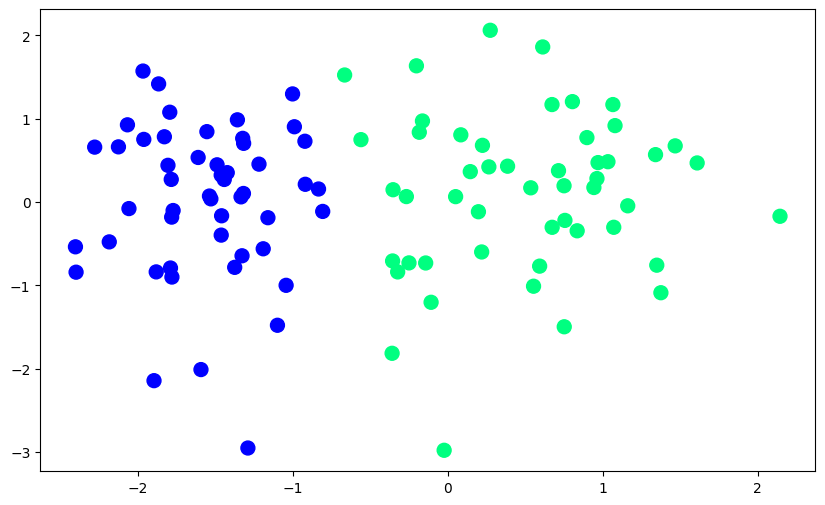

In [67]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.show()

In [54]:
import numpy as np

class Perceptron:
    def __init__(self, lr=0.01, epochs=1000):
        self.lr = lr
        self.epochs = epochs
        self.weights = None

    def _step(self, z):
        return np.where(z > 0, 1, 0)

    def fit(self, X, y):
        X = np.insert(X, 0, 1, axis=1)
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)

        for _ in range(self.epochs):
            i = np.random.randint(n_samples)
            yhat = self._step(np.dot(X[i], self.weights))
            error = y[i] - yhat
            self.weights += self.lr * error * X[i]

        return self

In [68]:
model = Perceptron(lr=0.1, epochs=1200)

model.fit(X,y)

In [69]:
intercept_ = model.weights[0]
coef_ = model.weights[1:]
intercept_,coef_

(np.float64(0.30000000000000004), array([0.43268812, 0.03603196]))

In [70]:
m = - (coef_[0] / coef_[1])
b = - (intercept_ / coef_[1])

In [71]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

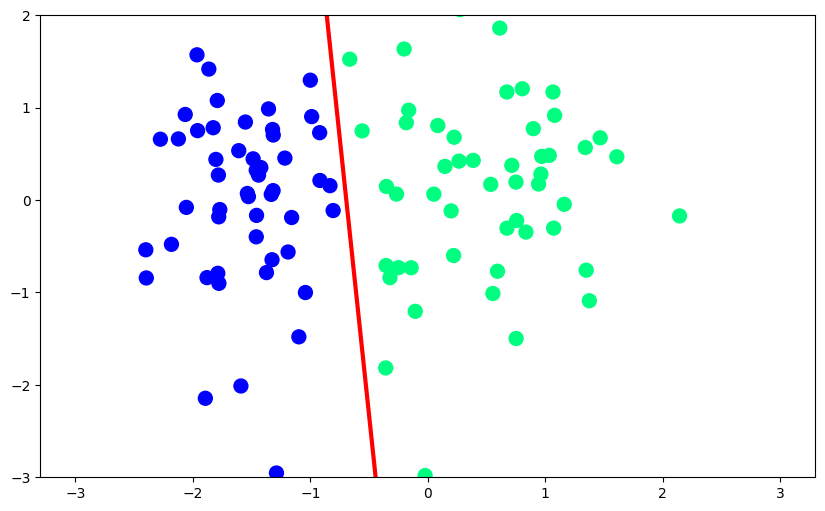

In [72]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)